# COVID-19 Data Analysis
### Exploratory Data Analysis with Pandas, Seaborn and Matplotlib

This project explores a country-level COVID-19 dataset. It follows the 25 tasks in the supplied *COVID-19 Data Analysis – Project 2* brief, including data inspection, cleaning, descriptive statistics, country rankings, continent-level aggregation, scatter plots and a Spearman-correlation heatmap.

**Dataset:** `COVID-19 Coronavirus.csv`  
**Important:** The dataset contains one missing value in `Other names`. As required by the brief, it is replaced with `Montenegro`. The analysis is descriptive and reflects the values present in the supplied dataset; it should not be interpreted as current COVID-19 surveillance data.

In [1]:
# 1. Import the required libraries and load the dataset
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

df = pd.read_csv("COVID-19 Coronavirus.csv")
print("Dataset loaded successfully.")

Dataset loaded successfully.


## 2–5. Initial dataset inspection

In [2]:
# 2. Display the shape of the dataset
print("Dataset shape (rows, columns):", df.shape)

# 3. Display the first five rows
display(df.head())

# 4. Display the last five rows
display(df.tail())

# 5. Display dataset information, column names and data types
print("Column names:", df.columns.tolist())
df.info()

Dataset shape (rows, columns): (225, 10)


,Country,Other names,ISO 3166-1 alpha-3 CODE,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
0,Afghanistan,Afghanistan,AFG,40462186,Asia,177827,7671,4395,190,4.313743
1,Albania,Albania,ALB,2872296,Europe,273870,3492,95349,1216,1.275058
2,Algeria,Algeria,DZA,45236699,Africa,265691,6874,5873,152,2.587216
3,Andorra,Andorra,AND,77481,Europe,40024,153,516565,1975,0.382271
4,Angola,Angola,AGO,34654212,Africa,99194,1900,2862,55,1.915438


,Country,Other names,ISO 3166-1 alpha-3 CODE,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
220,Wallis and Futuna,Wallis and Futuna Islands,WLF,10894,Oceania,454,7,41674,643,1.541850
221,Western Sahara,Western Sahara,ESHÂ,623031,Africa,10,1,16,2,10.000000
222,Yemen,Yemen,YEM,30975258,Asia,11806,2143,381,69,18.151787
223,Zambia,Zambia,ZMB,19284482,Africa,317076,3967,16442,206,1.251120
224,Zimbabwe,Zimbabwe,ZWE,15241601,Africa,246525,5446,16174,357,2.209107


Column names: ['Country', 'Other names', 'ISO 3166-1 alpha-3 CODE', 'Population', 'Continent', 'Total Cases', 'Total Deaths', 'Tot\xa0Cases//1M pop', 'Tot\xa0Deaths/1M pop', 'Death percentage']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225 entries, 0 to 224
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Country                  225 non-null    object 
 1   Other names              224 non-null    object 
 2   ISO 3166-1 alpha-3 CODE  225 non-null    object 
 3   Population               225 non-null    int64  
 4   Continent                225 non-null    object 
 5   Total Cases              225 non-null    int64  
 6   Total Deaths             225 non-null    int64  
 7   Tot Cases//1M pop        225 non-null    int64  
 8   Tot Deaths/1M pop        225 non-null    int64  
 9   Death percentage         225 non-null    float64
dtypes: float64(1), int64(5), object(4)
memory usage:

## 6–9. Missing-value inspection and cleaning

In [3]:
# 6. Check missing values in each column
print(df.isnull().sum())

# 7. Display rows containing missing values
missing_rows = df[df.isnull().any(axis=1)]
display(missing_rows)

# 8. Replace the missing value with 'Montenegro'
df["Other names"] = df["Other names"].fillna("Montenegro")

# 9. Verify row 135 (using zero-based row indexing)
display(df.iloc[[135]])
print("Missing values after replacement:", int(df.isnull().sum().sum()))

Country                    0
Other names                1
ISO 3166-1 alpha-3 CODE    0
Population                 0
Continent                  0
Total Cases                0
Total Deaths               0
Tot Cases//1M pop          0
Tot Deaths/1M pop          0
Death percentage           0
dtype: int64


,Country,Other names,ISO 3166-1 alpha-3 CODE,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
135,Montenegro,NaN,MNE,628205,Europe,233326,2705,371417,4306,1.159322


,Country,Other names,ISO 3166-1 alpha-3 CODE,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
135,Montenegro,Montenegro,MNE,628205,Europe,233326,2705,371417,4306,1.159322


Missing values after replacement: 0


## 10–11. Descriptive statistics and column renaming

In [4]:
# 10. Generate descriptive statistical summary
display(df.describe(include="all"))

# 11. Rename the ISO code column and display the first four rows
df.rename(columns={"ISO 3166-1 alpha-3 CODE": "Iso_Code"}, inplace=True)
display(df.head(4))

,Country,Other names,ISO 3166-1 alpha-3 CODE,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
count,225,225,225,2.250000e+02,225,2.250000e+02,2.250000e+02,225.000000,225.000000,225.000000
unique,225,225,225,NaN,6,NaN,NaN,NaN,NaN,NaN
top,Afghanistan,Afghanistan,AFG,NaN,Africa,NaN,NaN,NaN,NaN,NaN
freq,1,1,1,NaN,58,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,3.507321e+07,NaN,2.184781e+06,2.744813e+04,136900.373333,1096.715556,1.444125
std,NaN,NaN,NaN,1.392418e+08,NaN,7.275938e+06,9.689177e+04,145060.340289,1195.715543,1.741728
min,NaN,NaN,NaN,8.050000e+02,NaN,1.000000e+00,0.000000e+00,9.000000,0.000000,0.000000
25%,NaN,NaN,NaN,5.665570e+05,NaN,2.407100e+04,1.890000e+02,11384.000000,123.000000,0.511291
50%,NaN,NaN,NaN,5.827911e+06,NaN,1.639360e+05,1.965000e+03,88987.000000,708.000000,1.036905
75%,NaN,NaN,NaN,2.190585e+07,NaN,1.092547e+06,1.366000e+04,223335.000000,1795.000000,1.977017


,Country,Other names,Iso_Code,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
0,Afghanistan,Afghanistan,AFG,40462186,Asia,177827,7671,4395,190,4.313743
1,Albania,Albania,ALB,2872296,Europe,273870,3492,95349,1216,1.275058
2,Algeria,Algeria,DZA,45236699,Africa,265691,6874,5873,152,2.587216
3,Andorra,Andorra,AND,77481,Europe,40024,153,516565,1975,0.382271


## 12–20. Country-level case and death analysis

,Country,Total Cases
214,USA,81839052
92,India,43029044
26,Brazil,29999816
70,France,25997852
76,Germany,21646375


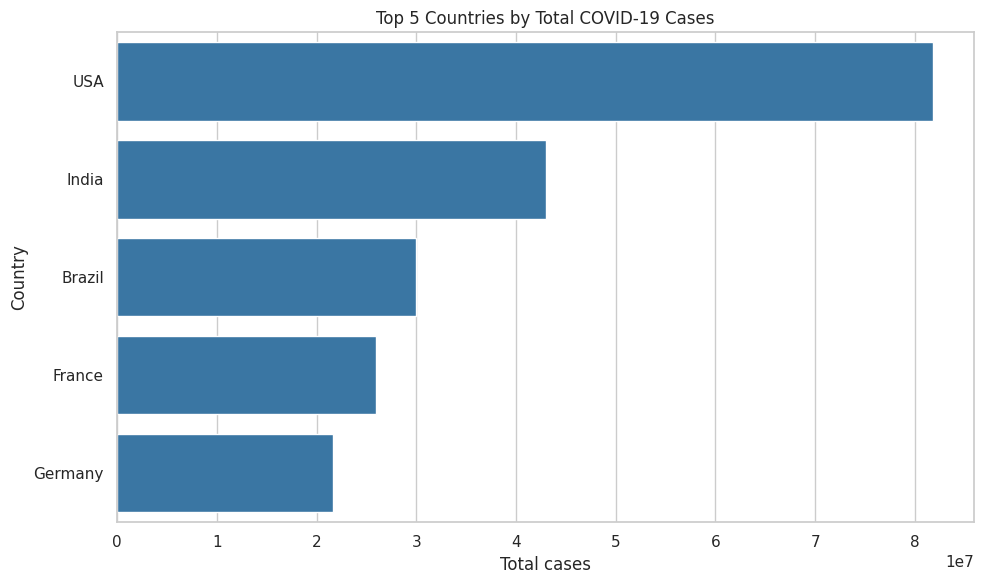

,Country,Total Cases
131,Micronesia,1
168,Saint Helena,2
125,Marshall Islands,7
148,Niue,7
221,Western Sahara,10


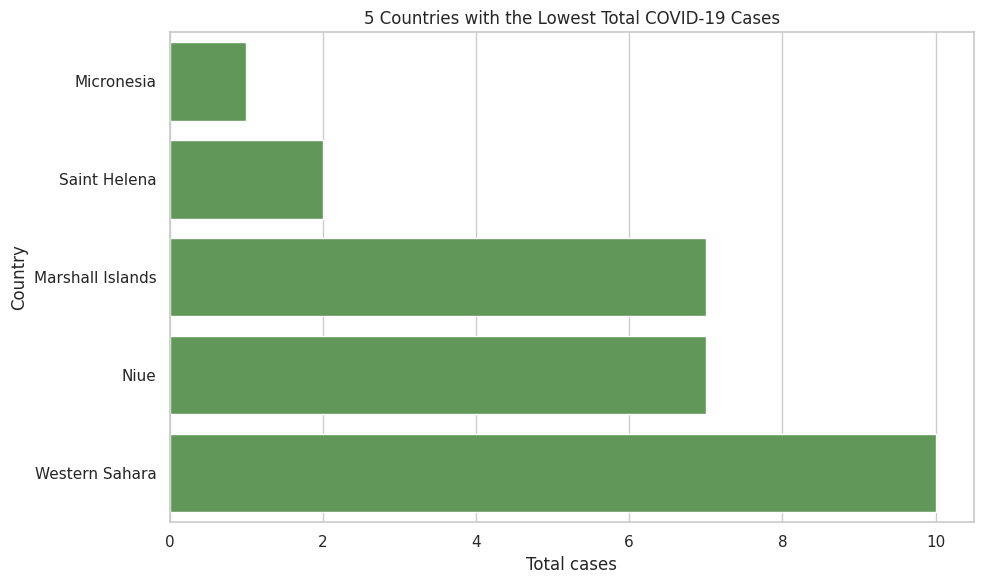

,Country,Total Deaths
214,USA,1008222
26,Brazil,660269
92,India,521388
165,Russia,369708
130,Mexico,323212


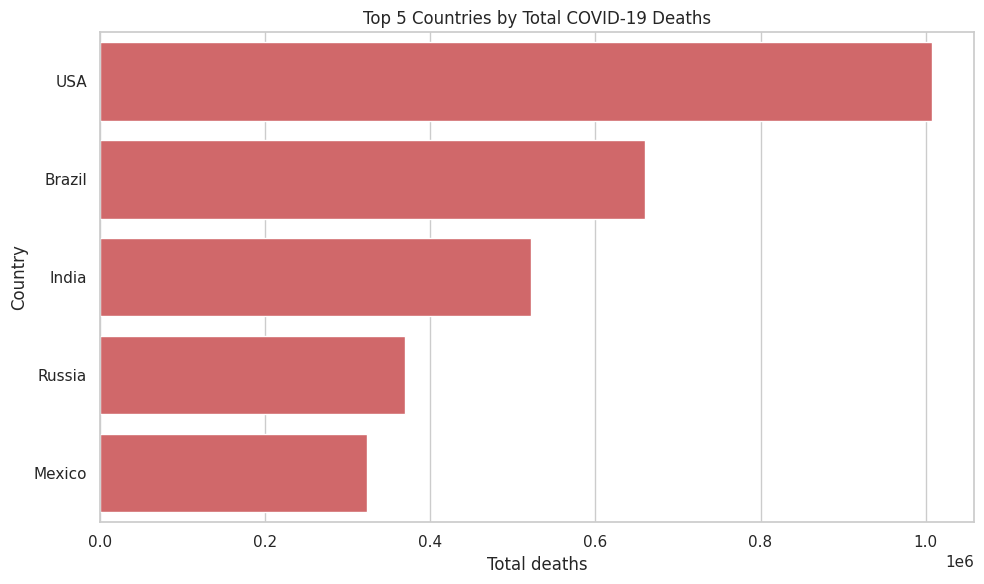

,Country,Total Deaths
46,Cook Islands,0
67,Falkland Islands,0
118,Macao,0
125,Marshall Islands,0
131,Micronesia,0


,Country,Death percentage
222,Yemen,18.151787
221,Western Sahara,10.000000
193,Sudan,7.920265
158,Peru,5.983499
130,Mexico,5.705041


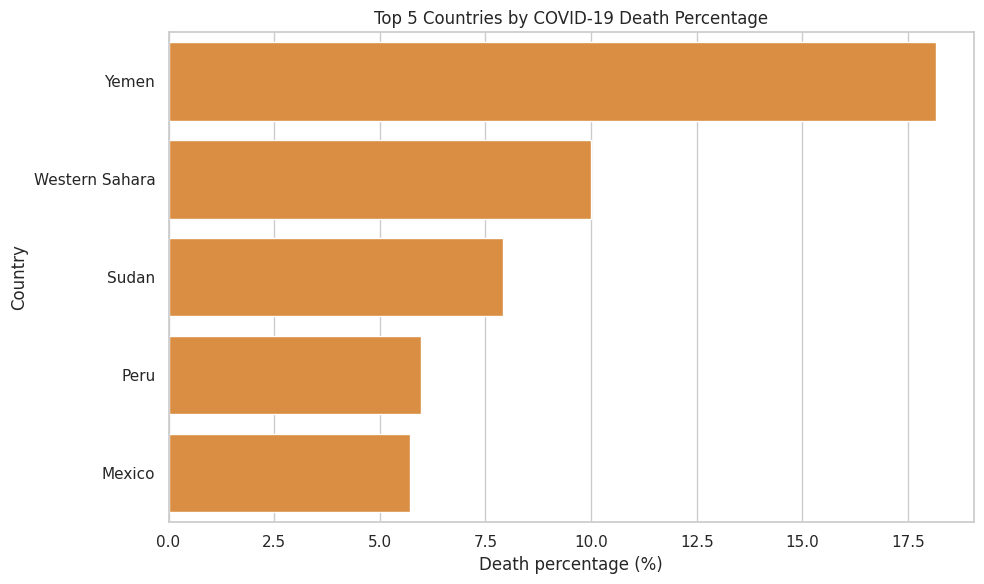

In [5]:
# 12. Five countries with the highest total COVID-19 cases
top_cases = df.nlargest(5, "Total Cases")[["Country", "Total Cases"]]
display(top_cases)

# 13. Bar plot: top five countries by total cases
plt.figure(figsize=(10, 6))
sns.barplot(data=top_cases, x="Total Cases", y="Country", color="#2878B5")
plt.title("Top 5 Countries by Total COVID-19 Cases")
plt.xlabel("Total cases")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/01_top_5_cases.png", dpi=200)
plt.show()

# 14. Five countries with the lowest total COVID-19 cases
lowest_cases = df.nsmallest(5, "Total Cases")[["Country", "Total Cases"]]
display(lowest_cases)

# 15. Bar plot: five countries with the lowest total cases
plt.figure(figsize=(10, 6))
sns.barplot(data=lowest_cases, x="Total Cases", y="Country", color="#59A14F")
plt.title("5 Countries with the Lowest Total COVID-19 Cases")
plt.xlabel("Total cases")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/02_lowest_5_cases.png", dpi=200)
plt.show()

# 16. Five countries with the highest total COVID-19 deaths
top_deaths = df.nlargest(5, "Total Deaths")[["Country", "Total Deaths"]]
display(top_deaths)

# 17. Bar plot: top five countries by total deaths
plt.figure(figsize=(10, 6))
sns.barplot(data=top_deaths, x="Total Deaths", y="Country", color="#E15759")
plt.title("Top 5 Countries by Total COVID-19 Deaths")
plt.xlabel("Total deaths")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/03_top_5_deaths.png", dpi=200)
plt.show()

# 18. Five countries with the lowest total COVID-19 deaths
lowest_deaths = df.nsmallest(5, "Total Deaths")[["Country", "Total Deaths"]]
display(lowest_deaths)

# 19. Five countries with the highest COVID-19 death percentage
top_death_pct = df.nlargest(5, "Death percentage")[["Country", "Death percentage"]]
display(top_death_pct)

# 20. Bar plot: top five countries by death percentage
plt.figure(figsize=(10, 6))
sns.barplot(data=top_death_pct, x="Death percentage", y="Country", color="#F28E2B")
plt.title("Top 5 Countries by COVID-19 Death Percentage")
plt.xlabel("Death percentage (%)")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/04_top_5_death_percentage.png", dpi=200)
plt.show()

## 21–22. Continent-wise analysis

Continent
Africa                              11764207
Asia                               140957179
Europe                             180332483
Latin America and the Caribbean     67509231
Northern America                    85364770
Oceania                              5647957
Name: Total Cases, dtype: int64

,Continent,Total Cases
0,Africa,11764207
1,Asia,140957179
2,Europe,180332483
3,Latin America and the Caribbean,67509231
4,Northern America,85364770
5,Oceania,5647957


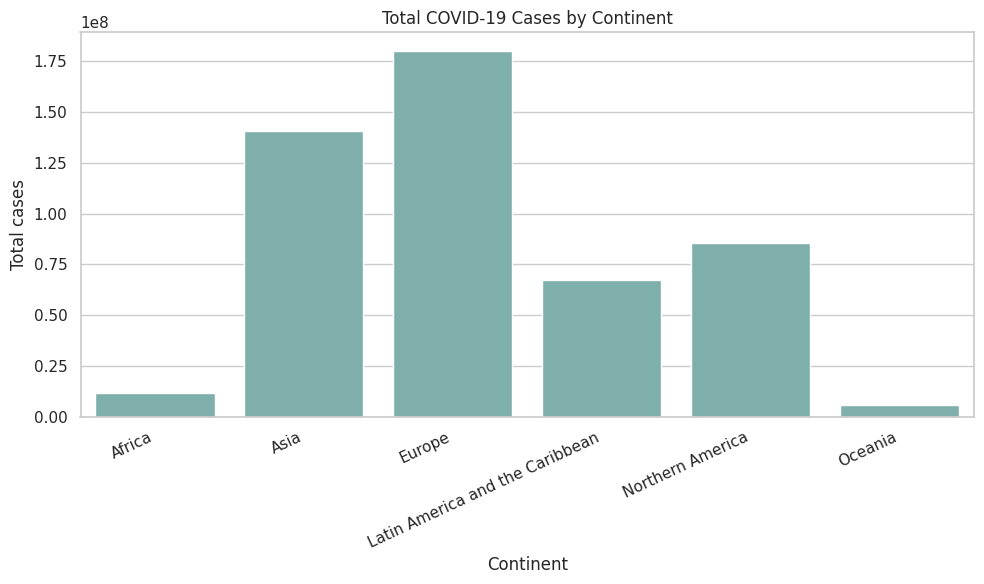

In [6]:
# 21. Calculate total COVID-19 cases continent-wise using groupby()
continent_cases = df.groupby("Continent")["Total Cases"].sum()
display(continent_cases)

# 22. Reset the index and create a bar plot
continent_cases_df = continent_cases.reset_index()
display(continent_cases_df)

plt.figure(figsize=(10, 6))
sns.barplot(data=continent_cases_df, x="Continent", y="Total Cases", color="#76B7B2")
plt.title("Total COVID-19 Cases by Continent")
plt.xlabel("Continent")
plt.ylabel("Total cases")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/05_cases_by_continent.png", dpi=200)
plt.show()

## 23–24. Relationship between numerical variables

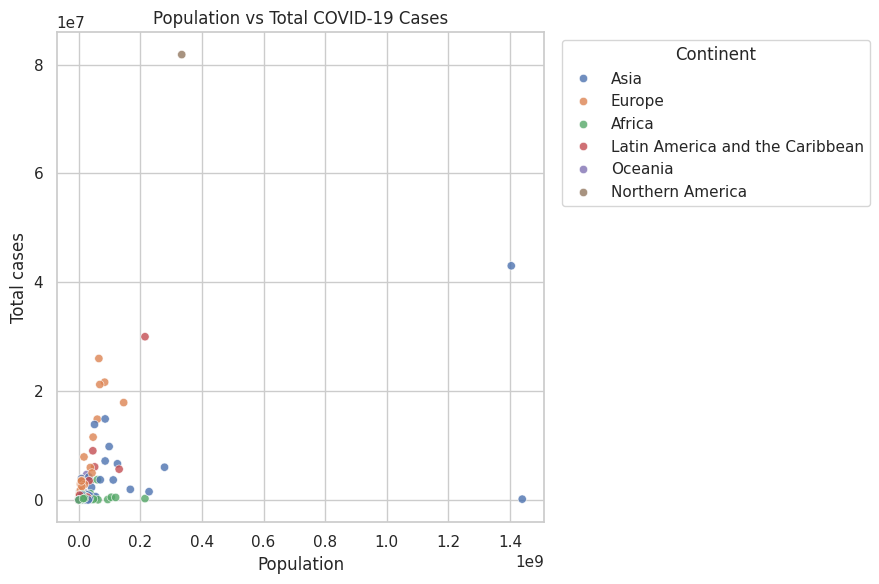

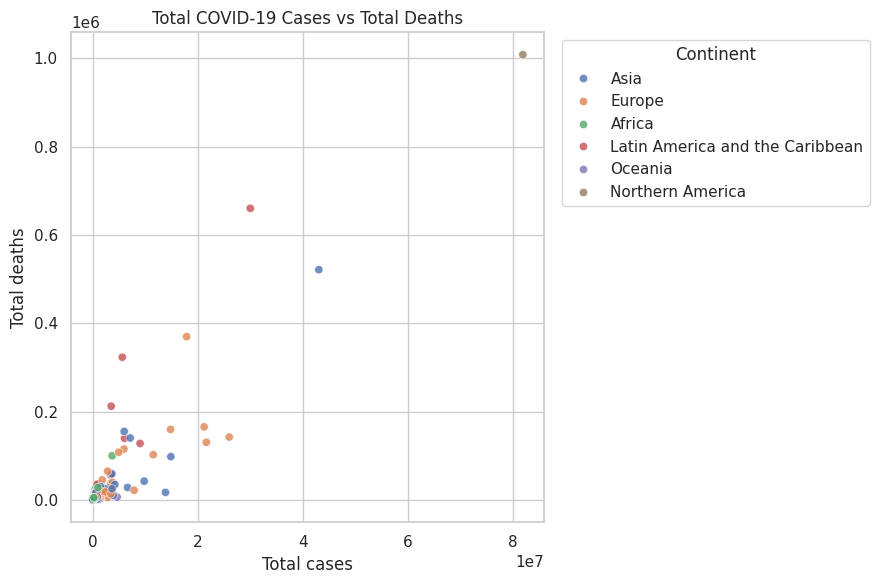

In [7]:
# 23. Scatter plot: Population vs Total Cases
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="Population", y="Total Cases", hue="Continent", alpha=0.8)
plt.title("Population vs Total COVID-19 Cases")
plt.xlabel("Population")
plt.ylabel("Total cases")
plt.legend(title="Continent", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/06_population_vs_cases.png", dpi=200)
plt.show()

# 24. Scatter plot: Total Cases vs Total Deaths
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="Total Cases", y="Total Deaths", hue="Continent", alpha=0.8)
plt.title("Total COVID-19 Cases vs Total Deaths")
plt.xlabel("Total cases")
plt.ylabel("Total deaths")
plt.legend(title="Continent", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/07_cases_vs_deaths.png", dpi=200)
plt.show()

## 25. Spearman correlation and heatmap

,Population,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
Population,1.000000,0.687202,0.777911,-0.337995,-0.075012,0.473551
Total Cases,0.687202,1.000000,0.936754,0.360762,0.508911,0.125393
Total Deaths,0.777911,0.936754,1.000000,0.165149,0.497638,0.420970
Tot Cases//1M pop,-0.337995,0.360762,0.165149,1.000000,0.760715,-0.464251
Tot Deaths/1M pop,-0.075012,0.508911,0.497638,0.760715,1.000000,0.113898
Death percentage,0.473551,0.125393,0.420970,-0.464251,0.113898,1.000000


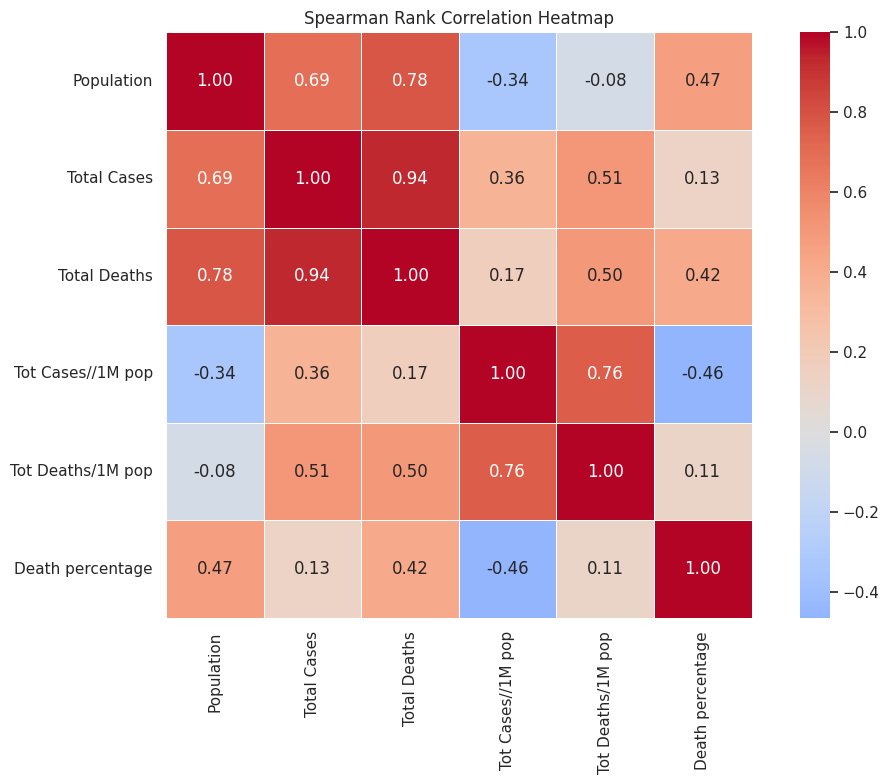

In [8]:
# 25. Calculate Spearman rank correlation for numerical columns
numeric_df = df.select_dtypes(include="number")
spearman_corr = numeric_df.corr(method="spearman")
display(spearman_corr)

plt.figure(figsize=(11, 8))
sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, linewidths=0.5, square=True)
plt.title("Spearman Rank Correlation Heatmap")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/08_spearman_correlation_heatmap.png", dpi=200)
plt.show()

## Conclusion

This exploratory analysis completes the requested data-inspection, cleaning, statistical-summary and visualization tasks. The country rankings identify the largest and smallest reported totals in the supplied file, while continent aggregation compares totals across continents. The scatter plots show how population, cases and deaths vary together, and the Spearman heatmap summarizes monotonic relationships among the numerical variables.

**Interpretation note:** Total counts are influenced by population size and reporting practices. Death percentage is a separate measure from total deaths, so the rankings can differ. Correlation indicates association, not causation.